In [1]:
# !pip install sqldf
# !pip install seaborn

In [2]:
from IPython.core.display import display, HTML

display(HTML("""
<style>
    .container {
        width: 95% !important;  /* Ajuste a largura conforme desejado (por exemplo, 95%) */
    }
</style>
"""))


In [3]:
import io
import ipywidgets as widgets
from ipywidgets import Output
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import re
import sqldf
import numpy as np
import seaborn as sns

# Criando as variáveis "globais"

out = Output()
out_hist = Output()
path_to_project = '/home/wsl/git/Wf-Security/heuristic_and_exact_solutions/'
# output_folder = 'output/20250606082527/'
# output_folder = 'output/20250624093837/'
# output_folder = 'output/20250713174847/'
output_folder = 'output/20250714102615/'
output_file_name = 'wf_security_executions.csv'
file_name = path_to_project + output_folder + output_file_name

# Setting Graphics Style - White background with grid lines (horizontal and vertical)

sns.set_style("whitegrid")

# Colors

# (red, green, blue, transparency)
colorGRASP = (0.229, 0.245, 0.249, 0.3)
colorExact = (0.15, 0.3, 0.74, 0.3)

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

def get_data(alphas, measure):
    # Collecting Plotting Data

    executions = pd.read_csv(file_name, header='infer')

    # Removing unnecessaries columns

    executions = executions.drop(columns=['scenario', 'alpha_restricted_candidate_list', 'num_clouds', 'num_vm', 'num_buckets', 'num_crypt_requirements', 'cloud_type', 
                                          'num_allocation_experiments', 'num_conf_requirements', 'num_iterations', 'best_solution_iteration', 'best_solution_time', 
                                          'lsn_time_1', 'lsn_noi_1', 'lsn_time_2', 'lsn_noi_2', 'lsn_time_3', 'lsn_noi_3', 'time', 'object_function'])

    # Filtering Data

#     executions = executions[(executions.alpha_time == 0.99) & (executions.alpha_cost == 0.005) & (executions.alpha_security == 0.005)]
    # executions = executions[(executions.alpha_time == 0.005) & (executions.alpha_cost == 0.99) & (executions.alpha_security == 0.005)]
    # executions = executions[(executions.alpha_time == 0.005) & (executions.alpha_cost == 0.005) & (executions.alpha_security == 0.99)]
#     print(alphas)
    executions = executions[(executions.alpha_time == alphas[0]) & (executions.alpha_cost == alphas[1]) & (executions.alpha_security == alphas[2])]
    
    if executions.empty:
        raise ValueError("Empty DataFrame after filtering alphas")
        
    # Renaming columns for reduce the table size

    alias = {"num_iterations": "n_iter", "makespan": "mspn", "cost": "cost", "security": "security", "time": "time", 'alpha_restricted_candidate_list': 'RCL', 'alpha_time': 'a_t', 'alpha_cost': 'a_c', 'alpha_security': 'a_s', 'algorithm': 'lgrthm'}
    executions = executions.rename(columns=alias)

    # Calculate mean and standard deviation

    desired_columns = ['mspn', 'cost', 'security']
    grouped = executions.groupby(['lgrthm', 'instance', 'a_t', 'a_c', 'a_s'])[desired_columns]
    mean_values = grouped.mean()
    std_values = grouped.std()

    # Rename standard deviation columns to the of the related column with "_std" appended

    std_values = std_values.rename(columns=lambda x: f"{x}_std")

    # Concatenate means and standard deviations

    grouped_executions = pd.concat([mean_values, std_values], axis=1)

    # Rearrange columns to standard devian follow corresponding mean column

    ordered_columns = []
    for col in desired_columns:
        ordered_columns.append(col)
        ordered_columns.append(f"{col}_std")

    grouped_executions = grouped_executions[ordered_columns]

    # Ordering Lines

    grouped_executions_sorted = grouped_executions.sort_values(by=['instance', 'lgrthm'], ascending=True)

    # Removing some columns off the index

    grouped_executions = grouped_executions.reset_index(level=['a_t', 'a_c', 'a_s'], drop=True)

    # Zeroing index to define the selected metric
    
    df = grouped_executions.reset_index()

    if measure == "makespan":
        metric = 'mspn'
    elif measure == "cost":
        metric = 'cost'
    elif measure == "security":
        metric = 'security'
    else:
        raise ValueError(f"Invalid metric: {metric}")

    metric_std = metric + '_std'

    # Pivotar o DataFrame para ter instâncias no eixo X e algoritmos como colunas
    pivoted = df.pivot(index='instance', columns='lgrthm', values=metric)
    pivoted_std = df.pivot(index='instance', columns='lgrthm', values=metric_std)
    
    return pivoted, pivoted_std

In [4]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
# grouped_executions

In [5]:
data, err = get_data([0.99, 0.005, 0.005], 'makespan')
# data['CYCLOPS']

<function matplotlib.pyplot.plot(*args, scalex=True, scaley=True, data=None, **kwargs)>

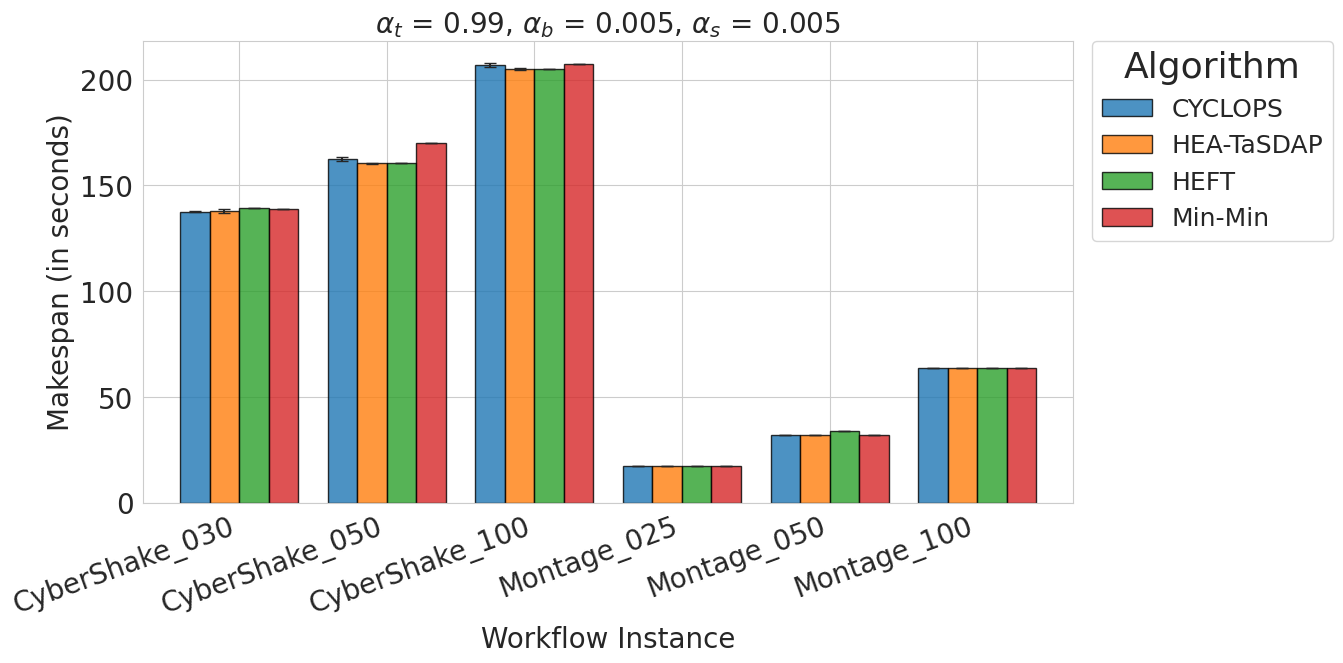

In [6]:
# Plot #1 - 0.99, 0.005, 0.005 - Makespan

data, err = get_data([0.99, 0.005, 0.005], 'makespan')

ax = data.plot(kind='bar', yerr=err, figsize=(12, 6), capsize=4, edgecolor='black', width=0.8, alpha=0.8)

# Define texts

# ax.legend(title='Algorithm')
# ax.legend(title='Algorithm', loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=len(ax.get_legend().get_texts()))
ax.legend(title='Algorithm',
          loc='upper left',
          bbox_to_anchor=(1.02, 1),
          borderaxespad=0,
          fontsize=18,
          title_fontsize=26)
plt.title(r'$\alpha_t$ = 0.99, $\alpha_b$ = 0.005, $\alpha_s$ = 0.005', fontsize=20)
plt.xlabel("Workflow Instance", fontsize = 20)
plt.ylabel("Makespan (in seconds)", fontsize = 20)
plt.xticks(rotation=20, ha='right', fontsize=20)
plt.yticks(fontsize=20)

# f {paper, notebook, talk, poster}
sns.set_context("paper", font_scale=2.5, rc={"lines.linewidth": 1.5})

plt.savefig("./09_05_05_Makespan.png",bbox_inches='tight')

plt.plot

<function matplotlib.pyplot.plot(*args, scalex=True, scaley=True, data=None, **kwargs)>

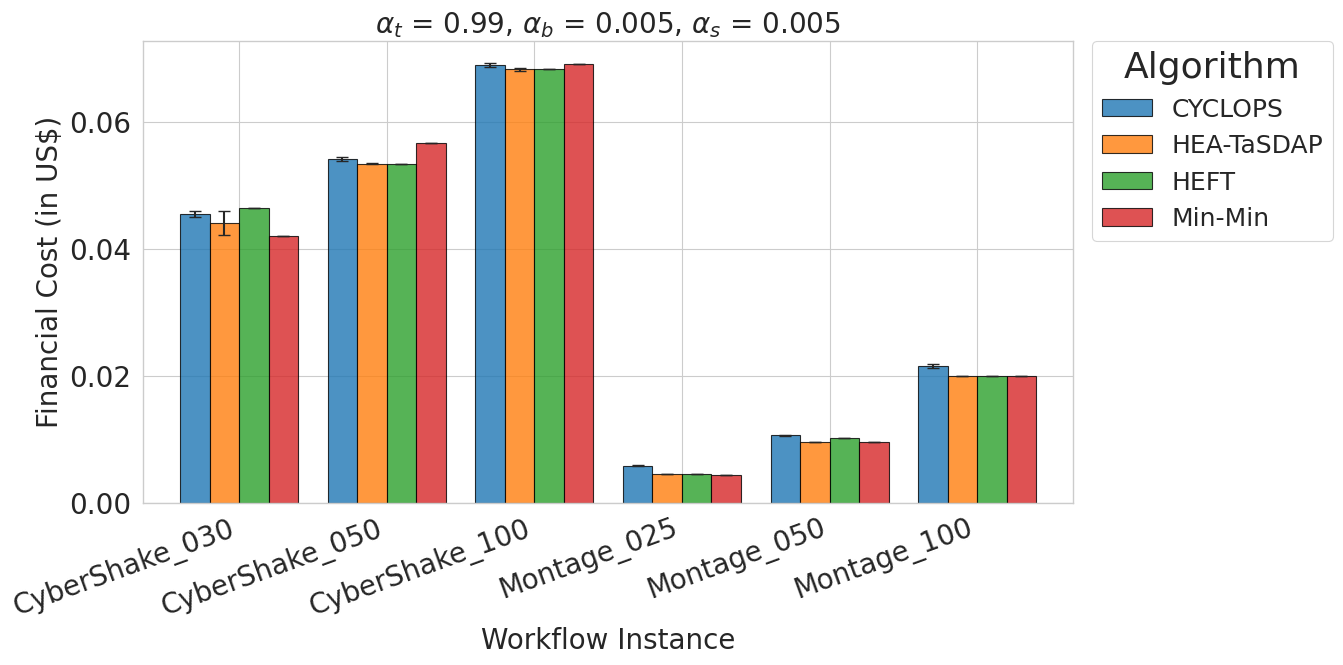

In [7]:
# Plot #2 - 0.99, 0.005, 0.005 - Cost

data, err = get_data([0.99, 0.005, 0.005], 'cost')

ax = data.plot(kind='bar', yerr=err, figsize=(12, 6), capsize=4, edgecolor='black', width=0.8, alpha=0.8)

# Define texts

# ax.legend(title='Algorithm')
ax.legend(title='Algorithm',
          loc='upper left',
          bbox_to_anchor=(1.02, 1),
          borderaxespad=0,
          fontsize=18,
          title_fontsize=26)
plt.title(r'$\alpha_t$ = 0.99, $\alpha_b$ = 0.005, $\alpha_s$ = 0.005', fontsize=20)
plt.xlabel("Workflow Instance", fontsize = 20)
plt.ylabel("Financial Cost (in US$)", fontsize = 20)
plt.xticks(rotation=20, ha='right', fontsize=20)
plt.yticks(fontsize=20)

# f {paper, notebook, talk, poster}
sns.set_context("paper", font_scale=2.5, rc={"lines.linewidth": 1.5})

plt.savefig("./09_05_05_Cost.png",bbox_inches='tight')

plt.plot

<function matplotlib.pyplot.plot(*args, scalex=True, scaley=True, data=None, **kwargs)>

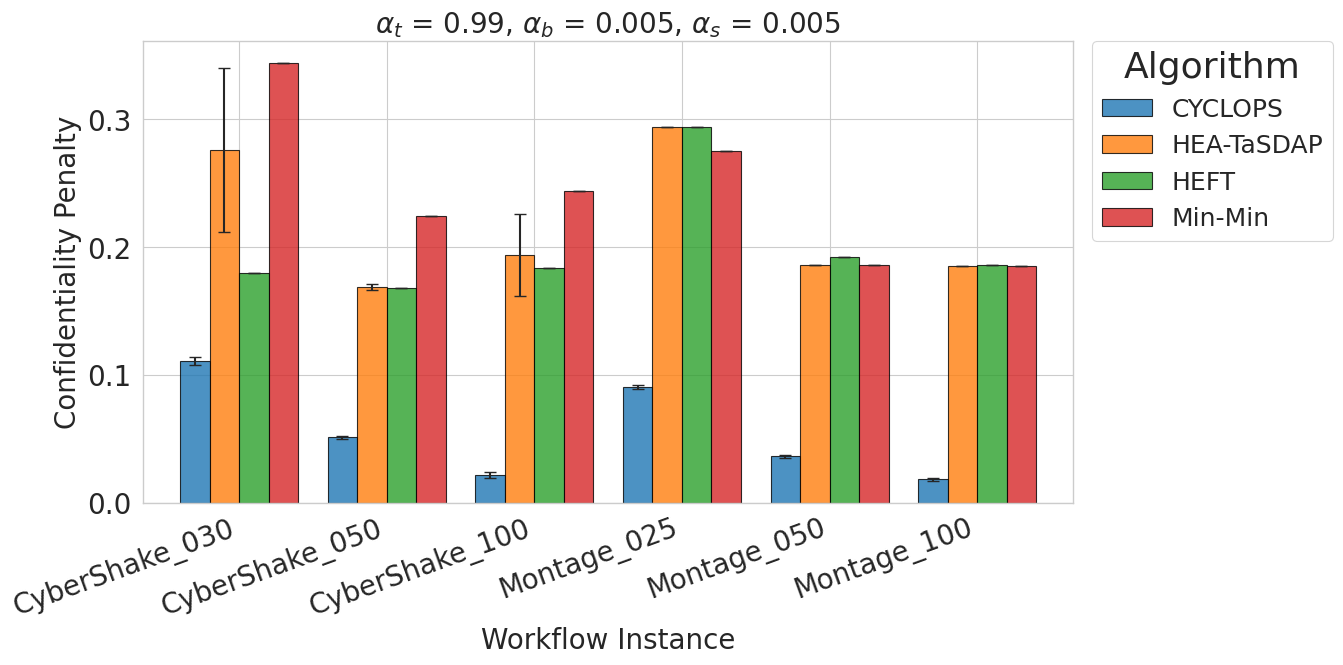

In [8]:
# Plot #3 - 0.99, 0.005, 0.005 - Security

data, err = get_data([0.99, 0.005, 0.005], 'security')

ax = data.plot(kind='bar', yerr=err, figsize=(12, 6), capsize=4, edgecolor='black', width=0.8, alpha=0.8)

# Define texts

# ax.legend(title='Algorithm')
ax.legend(title='Algorithm',
          loc='upper left',
          bbox_to_anchor=(1.02, 1),
          borderaxespad=0,
          fontsize=18,
          title_fontsize=26)
plt.title(r'$\alpha_t$ = 0.99, $\alpha_b$ = 0.005, $\alpha_s$ = 0.005', fontsize=20)
plt.xlabel("Workflow Instance", fontsize = 20)
plt.ylabel("Confidentiality Penalty", fontsize = 20)
plt.xticks(rotation=20, ha='right', fontsize=20)
plt.yticks(fontsize=20)

# f {paper, notebook, talk, poster}
sns.set_context("paper", font_scale=2.5, rc={"lines.linewidth": 1.5})

plt.savefig("./09_05_05_Security.png",bbox_inches='tight')

plt.plot

<function matplotlib.pyplot.plot(*args, scalex=True, scaley=True, data=None, **kwargs)>

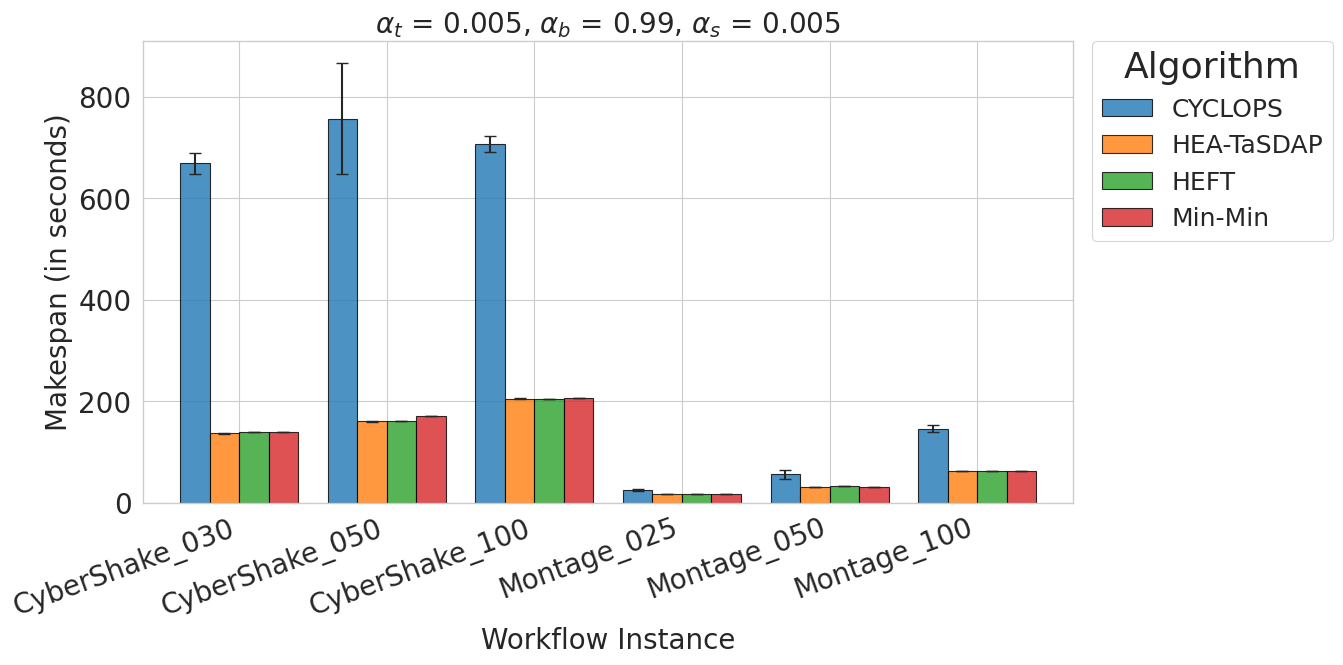

In [9]:
# Plot #4 - 0.005, 0.99, 0.005 - Makespan

data, err = get_data([0.005, 0.99, 0.005], 'makespan')

ax = data.plot(kind='bar', yerr=err, figsize=(12, 6), capsize=4, edgecolor='black', width=0.8, alpha=0.8)

# Define texts

# ax.legend(title='Algorithm')
ax.legend(title='Algorithm',
          loc='upper left',
          bbox_to_anchor=(1.02, 1),
          borderaxespad=0,
          fontsize=18,
          title_fontsize=26)
plt.title(r'$\alpha_t$ = 0.005, $\alpha_b$ = 0.99, $\alpha_s$ = 0.005', fontsize=20)
plt.xlabel("Workflow Instance", fontsize = 20)
plt.ylabel("Makespan (in seconds)", fontsize = 20)
plt.xticks(rotation=20, ha='right', fontsize=20)
plt.yticks(fontsize=20)

# f {paper, notebook, talk, poster}
sns.set_context("paper", font_scale=2.5, rc={"lines.linewidth": 1.5})

plt.savefig("./05_09_05_Makespan.png",bbox_inches='tight')

plt.plot

<function matplotlib.pyplot.plot(*args, scalex=True, scaley=True, data=None, **kwargs)>

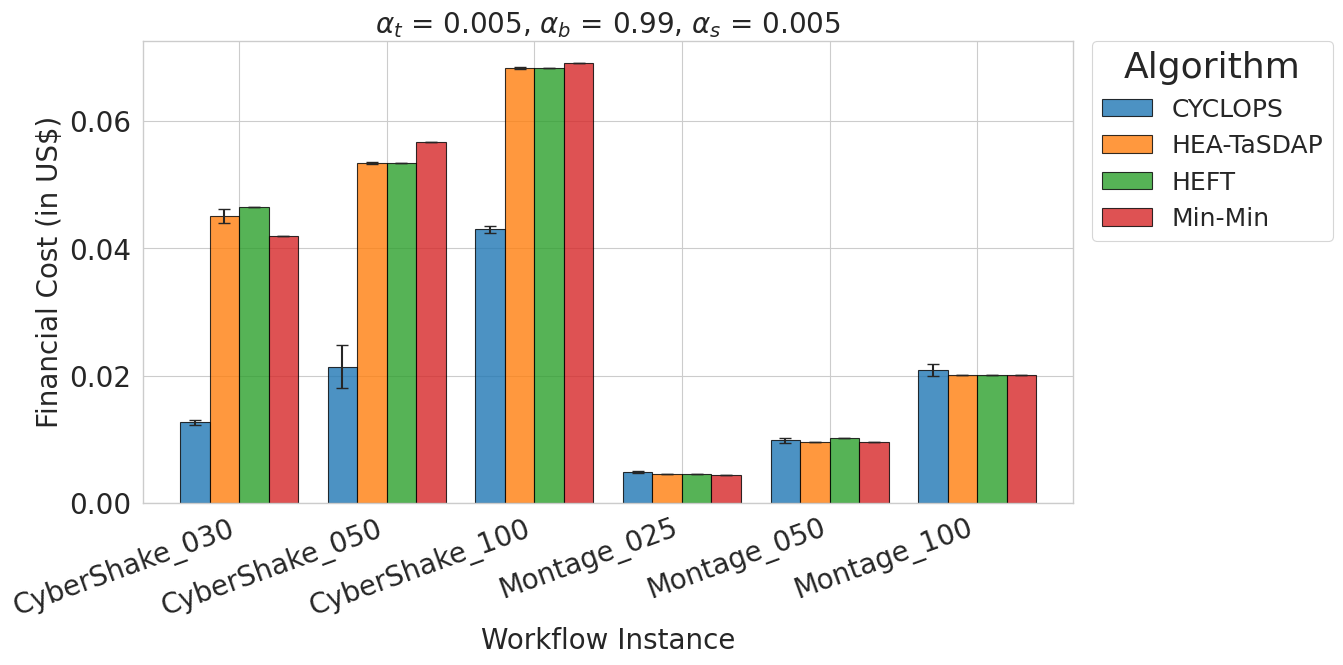

In [10]:
# Plot #5 - 0.005, 0.99, 0.005 - Cost

data, err = get_data([0.005, 0.99, 0.005], 'cost')

ax = data.plot(kind='bar', yerr=err, figsize=(12, 6), capsize=4, edgecolor='black', width=0.8, alpha=0.8)

# Define texts

# ax.legend(title='Algorithm')
ax.legend(title='Algorithm',
          loc='upper left',
          bbox_to_anchor=(1.02, 1),
          borderaxespad=0,
          fontsize=18,
          title_fontsize=26)
plt.title(r'$\alpha_t$ = 0.005, $\alpha_b$ = 0.99, $\alpha_s$ = 0.005', fontsize=20)
plt.xlabel("Workflow Instance", fontsize = 20)
plt.ylabel("Financial Cost (in US$)", fontsize = 20)
plt.xticks(rotation=20, ha='right', fontsize=20)
plt.yticks(fontsize=20)

# f {paper, notebook, talk, poster}
sns.set_context("paper", font_scale=2.5, rc={"lines.linewidth": 1.5})

plt.savefig("./05_09_05_Cost.png",bbox_inches='tight')

plt.plot

<function matplotlib.pyplot.plot(*args, scalex=True, scaley=True, data=None, **kwargs)>

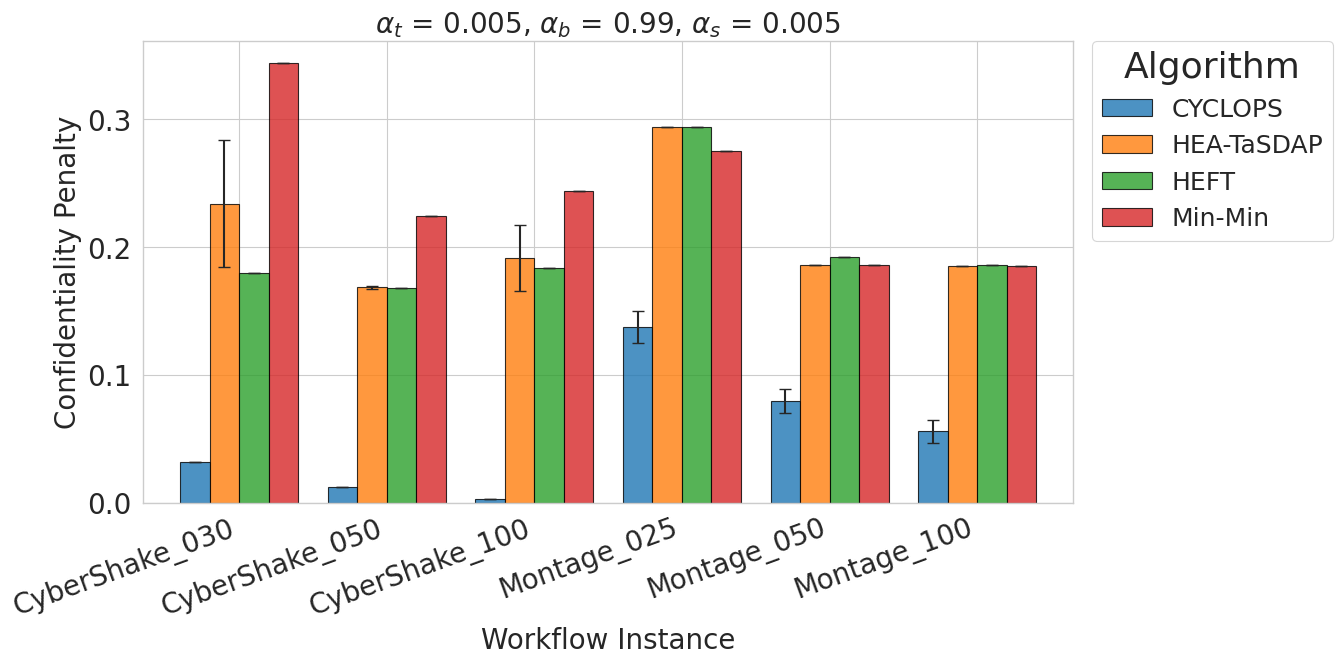

In [11]:
# Plot #6 - 0.005, 0.99, 0.005 - Security

data, err = get_data([0.005, 0.99, 0.005], 'security')

ax = data.plot(kind='bar', yerr=err, figsize=(12, 6), capsize=4, edgecolor='black', width=0.8, alpha=0.8)

# Define texts

# ax.legend(title='Algorithm')
ax.legend(title='Algorithm',
          loc='upper left',
          bbox_to_anchor=(1.02, 1),
          borderaxespad=0,
          fontsize=18,
          title_fontsize=26)
plt.title(r'$\alpha_t$ = 0.005, $\alpha_b$ = 0.99, $\alpha_s$ = 0.005', fontsize=20)
plt.xlabel("Workflow Instance", fontsize = 20)
plt.ylabel("Confidentiality Penalty", fontsize = 20)
plt.xticks(rotation=20, ha='right', fontsize=20)
plt.yticks(fontsize=20)

# f {paper, notebook, talk, poster}
sns.set_context("paper", font_scale=2.5, rc={"lines.linewidth": 1.5})

plt.savefig("./05_09_05_Security.png",bbox_inches='tight')

plt.plot

<function matplotlib.pyplot.plot(*args, scalex=True, scaley=True, data=None, **kwargs)>

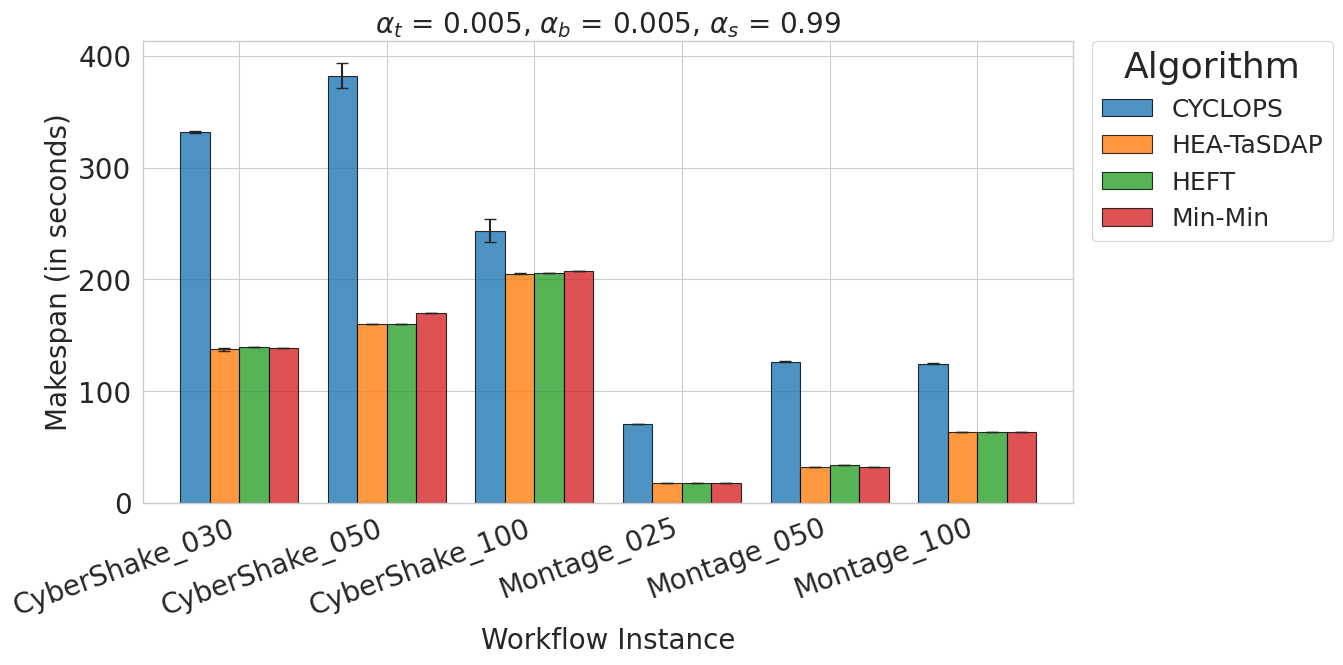

In [12]:
# Plot #7- 0.005, 0.005, 0.99 - Makespan

data, err = get_data([0.005, 0.005, 0.99], 'makespan')

ax = data.plot(kind='bar', yerr=err, figsize=(12, 6), capsize=4, edgecolor='black', width=0.8, alpha=0.8)

# Define texts

# ax.legend(title='Algorithm')
ax.legend(title='Algorithm',
          loc='upper left',
          bbox_to_anchor=(1.02, 1),
          borderaxespad=0,
          fontsize=18,
          title_fontsize=26)
plt.title(r'$\alpha_t$ = 0.005, $\alpha_b$ = 0.005, $\alpha_s$ = 0.99', fontsize=20)
plt.xlabel("Workflow Instance", fontsize = 20)
plt.ylabel("Makespan (in seconds)", fontsize = 20)
plt.xticks(rotation=20, ha='right', fontsize=20)
plt.yticks(fontsize=20)

# f {paper, notebook, talk, poster}
sns.set_context("paper", font_scale=2.5, rc={"lines.linewidth": 1.5})

plt.savefig("./05_05_09_Makespan.png",bbox_inches='tight')

plt.plot

<function matplotlib.pyplot.plot(*args, scalex=True, scaley=True, data=None, **kwargs)>

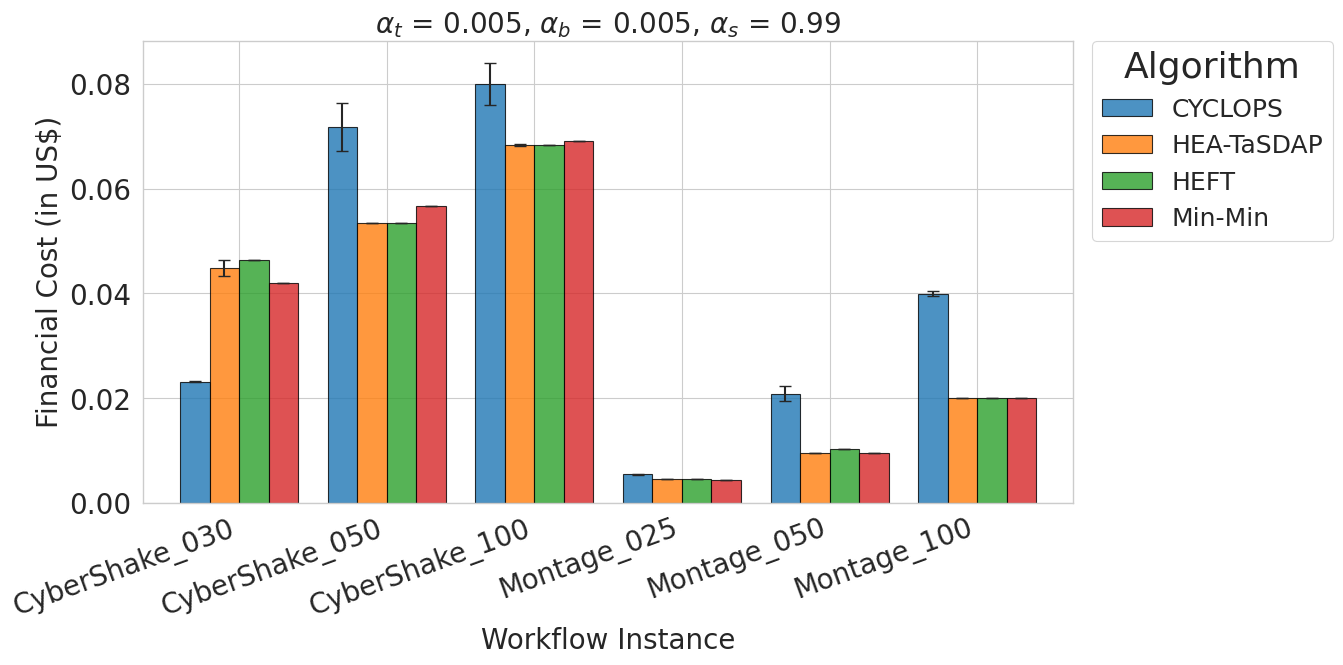

In [13]:
# Plot #8- 0.005, 0.005, 0.99 - Cost

data, err = get_data([0.005, 0.005, 0.99], 'cost')

ax = data.plot(kind='bar', yerr=err, figsize=(12, 6), capsize=4, edgecolor='black', width=0.8, alpha=0.8)

# Define texts

# ax.legend(title='Algorithm')
ax.legend(title='Algorithm',
          loc='upper left',
          bbox_to_anchor=(1.02, 1),
          borderaxespad=0,
          fontsize=18,
          title_fontsize=26)
plt.title(r'$\alpha_t$ = 0.005, $\alpha_b$ = 0.005, $\alpha_s$ = 0.99', fontsize=20)
plt.xlabel("Workflow Instance", fontsize = 20)
plt.ylabel("Financial Cost (in US$)", fontsize = 20)
plt.xticks(rotation=20, ha='right', fontsize=20)
plt.yticks(fontsize=20)

# f {paper, notebook, talk, poster}
sns.set_context("paper", font_scale=2.5, rc={"lines.linewidth": 1.5})

plt.savefig("./05_05_09_Cost.png",bbox_inches='tight')

plt.plot

<function matplotlib.pyplot.plot(*args, scalex=True, scaley=True, data=None, **kwargs)>

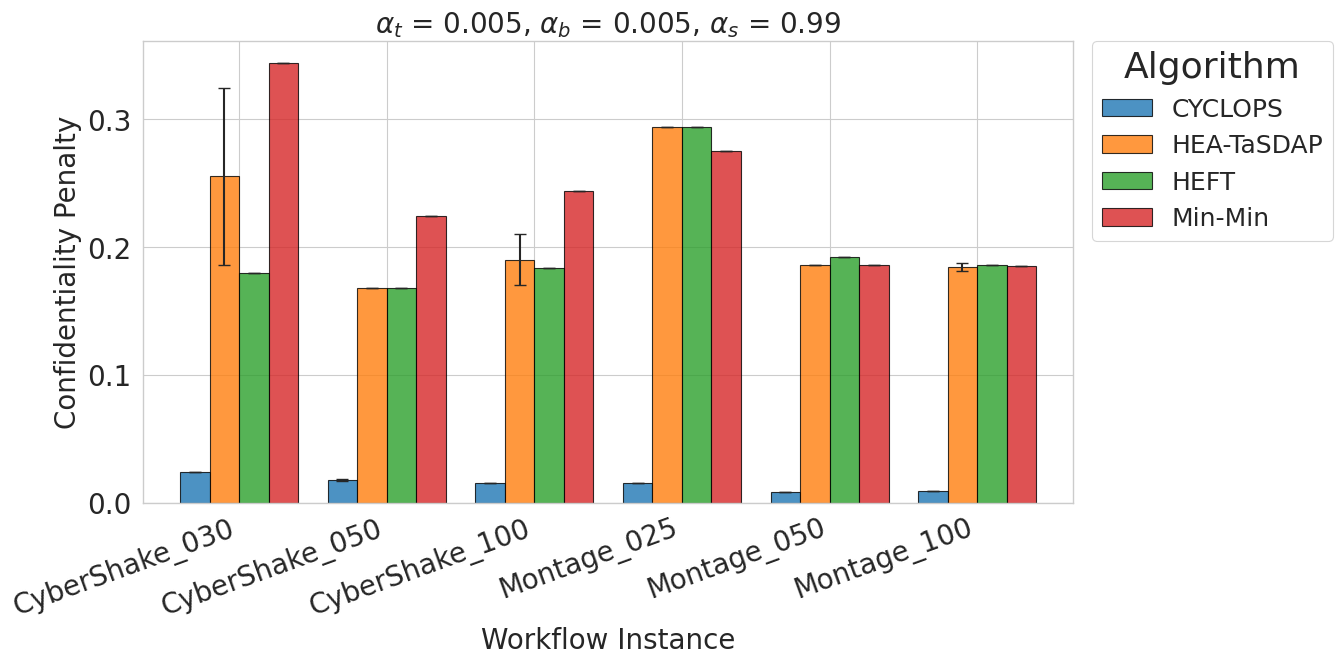

In [14]:
# Plot #9- 0.005, 0.005, 0.99 - Security

data, err = get_data([0.005, 0.005, 0.99], 'security')

ax = data.plot(kind='bar', yerr=err, figsize=(12, 6), capsize=4, edgecolor='black', width=0.8, alpha=0.8)

# Define texts

# ax.legend(title='Algorithm')
ax.legend(title='Algorithm',
          loc='upper left',
          bbox_to_anchor=(1.02, 1),
          borderaxespad=0,
          fontsize=18,
          title_fontsize=26)
plt.title(r'$\alpha_t$ = 0.005, $\alpha_b$ = 0.005, $\alpha_s$ = 0.99', fontsize=20)
plt.xlabel("Workflow Instance", fontsize = 20)
plt.ylabel("Confidentiality Penalty", fontsize = 20)
plt.xticks(rotation=20, ha='right', fontsize=20)
plt.yticks(fontsize=20)

# f {paper, notebook, talk, poster}
sns.set_context("paper", font_scale=2.5, rc={"lines.linewidth": 1.5})

plt.savefig("./05_05_09_Security.png",bbox_inches='tight')

plt.plot

In [15]:

# # Define and apply hachuras

# hatches = ['/', '\\', '|', '-']
# # hatches = ['/','/','/','/']
# for i, thisbar in enumerate(plot.containers):
#     for j, patch in enumerate(thisbar.get_children()):
#         patch.set_hatch(hatches[i % len(hatches)])
